# Опоздания доставки на маркетплейсе Olist

**Вопрос:** насколько опоздания доставки влияют на оценки покупателей и где эти опоздания возникают — у продавца или в доставке.

Данные — открытый датасет бразильского маркетплейса Olist: около 100 тыс. заказов с 2016 по 2018 год, 9 связанных таблиц (заказы, товары, продавцы, покупатели, оплаты, отзывы). Таблицы загружаю в DuckDB и основную подготовку делаю на SQL, запросы лежат в папке `sql/`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from scipy.stats import chi2_contingency

DATA = Path('../data')
SQL = Path('../sql')
IMG = Path('../images')

con = duckdb.connect()
tables = ['orders', 'order_items', 'order_reviews', 'customers', 'sellers']
for t in tables:
    con.execute(f"create view {t} as select * from read_csv_auto('{DATA / f'olist_{t}_dataset.csv'}')")

def run(name):
    return con.sql((SQL / name).read_text()).df()

# общий стиль графиков
BLUE, ORANGE, GRAY, INK = '#2a78d6', '#eb6834', '#b9b8b2', '#52514e'
plt.rcParams.update({
    'figure.figsize': (9, 4.2), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 10.5, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.grid': True, 'grid.color': '#e9e8e4', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

## 1. Подготовка данных

Сначала посмотрю на статусы заказов — опоздание имеет смысл считать только для доставленных.

In [2]:
con.sql("select order_status, count(*) as orders from orders group by 1 order by 2 desc").df()

,order_status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


97% заказов доставлены, остальные статусы для этого вопроса не нужны. В `01_orders_flat.sql` собираю плоскую таблицу: одна строка — один доставленный заказ. Пара решений, которые пришлось принять:

- **Опоздание** = фактическая дата доставки позже даты, которую маркетплейс показал покупателю при заказе (`order_estimated_delivery_date`). То есть опоздание относительно обещания, а не просто «долгая доставка».
- **Поздняя передача продавцом** = продавец передал заказ перевозчику позже крайнего срока `shipping_limit_date`.
- Отрезал хвосты: в 2016 году и после августа 2018 заказов единицы.
- У ~550 заказов больше одного отзыва — беру последний.

In [3]:
con.execute((SQL / '01_orders_flat.sql').read_text())
df = con.sql('select * from orders_flat').df()
print(f'Заказов: {len(df):,}'.replace(',', ' '))
print(f'Опоздали: {df.is_late.mean():.1%}')
print(f'Без отзыва: {df.review_score.isna().mean():.1%}')
df[['promised_days', 'actual_days', 'delay_days']].describe().round(1)

Заказов: 96 203
Опоздали: 8.1%
Без отзыва: 0.7%


,promised_days,actual_days,delay_days
count,96203.0,96203.0,96203.0
mean,24.3,12.5,-11.8
std,8.6,9.5,10.1
min,3.0,0.0,-147.0
25%,19.0,7.0,-17.0
50%,24.0,10.0,-12.0
75%,29.0,16.0,-7.0
max,156.0,210.0,188.0


Первое, что бросается в глаза: обещанный срок в среднем почти вдвое больше фактического (~24 дня против ~12). Маркетплейс закладывает большой запас, и всё равно примерно 8% заказов в него не укладываются.

## 2. Насколько опоздание бьёт по оценке

In [4]:
by_delay = run('02_delay_vs_review.sql')
by_delay

,delay_group,orders,avg_score,bad_review_pct
0,1. раньше срока на 7+ дн.,75487,4.31,9.0
1,2. в срок,13695,4.17,10.7
2,3. опоздание 1-3 дн.,1851,3.29,32.1
3,4. опоздание 4-7 дн.,1748,2.10,67.7
4,5. опоздание 8-14 дн.,1446,1.67,80.2
5,6. опоздание 15+ дн.,1333,1.72,78.3


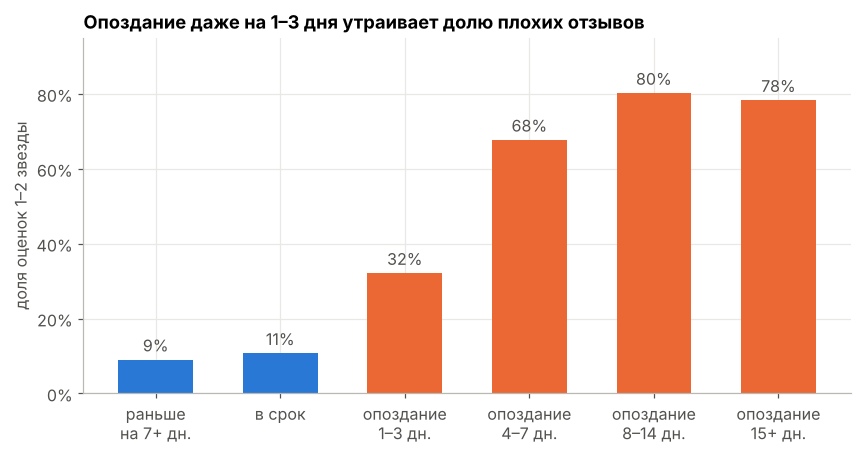

In [5]:
fig, ax = plt.subplots()
labels = ['раньше\nна 7+ дн.', 'в срок', 'опоздание\n1–3 дн.', 'опоздание\n4–7 дн.', 'опоздание\n8–14 дн.', 'опоздание\n15+ дн.']
colors = [BLUE if i < 2 else ORANGE for i in range(len(by_delay))]
bars = ax.bar(labels, by_delay.bad_review_pct, color=colors, width=0.6)
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in by_delay.bad_review_pct], padding=3, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 95)
ax.set_ylabel('доля оценок 1–2 звезды')
ax.set_title('Опоздание даже на 1–3 дня утраивает долю плохих отзывов')
fig.savefig(IMG / '01_delay_vs_bad_reviews.png')
plt.show()

In [6]:
rev = df.dropna(subset=['review_score'])
bad = rev.review_score <= 2
share_late_in_bad = rev.loc[bad, 'is_late'].mean()
print(f'Опоздавших заказов среди всех: {rev.is_late.mean():.1%}')
print(f'Опоздавших заказов среди плохих отзывов (1–2): {share_late_in_bad:.1%}')

Опоздавших заказов среди всех: 8.0%
Опоздавших заказов среди плохих отзывов (1–2): 33.9%


Зависимость очень резкая. Пока заказ приходит в срок, плохих отзывов около 10%. Опоздание на 1–3 дня — уже 32%, на неделю и больше — около 80%. При этом опоздавших заказов всего ~8%, но на них приходится примерно треть всех плохих отзывов.

Тут важно не перепутать причину и следствие, но в этом случае направление очевидно: отзыв пишется после доставки, и опоздание не может быть следствием отзыва. Хотя часть эффекта может давать что-то третье (например, плохие продавцы и опаздывают, и отправляют не тот товар).

## 3. Когда случаются опоздания

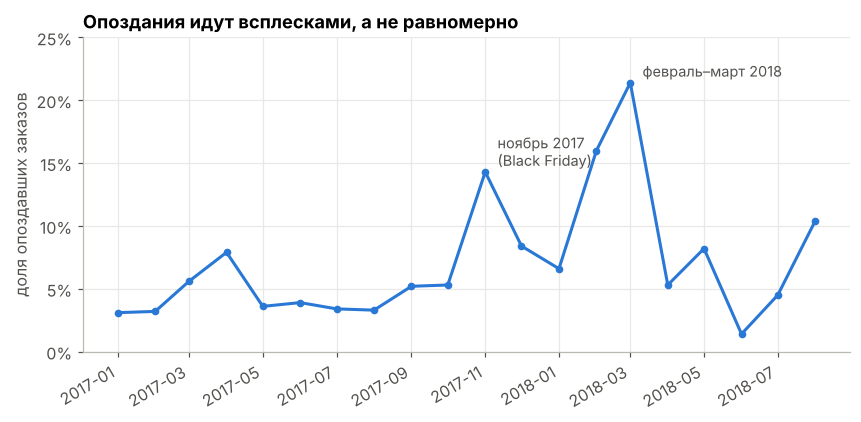

In [7]:
by_month = run('03_late_by_month.sql')
fig, ax = plt.subplots()
ax.plot(by_month.purchase_month, by_month.late_pct, color=BLUE, lw=2, marker='o', ms=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 25)
ax.set_ylabel('доля опоздавших заказов')
ax.set_title('Опоздания идут всплесками, а не равномерно')
for m, txt in [('2017-11-01', 'ноябрь 2017\n(Black Friday)'), ('2018-03-01', 'февраль–март 2018')]:
    row = by_month[by_month.purchase_month == m].iloc[0]
    ax.annotate(txt, (row.purchase_month, row.late_pct), xytext=(8, 4), textcoords='offset points', color=INK, fontsize=9.5)
fig.autofmt_xdate()
fig.savefig(IMG / '02_late_by_month.png')
plt.show()

В обычный месяц опаздывает 3–6% заказов. Но есть три всплеска: ноябрь 2017 (14%, Black Friday — заказов почти вдвое больше обычного), февраль–март 2018 (16% и 21%) и август 2018 (10%).

С ноябрём всё понятно — пиковая нагрузка. Причину всплеска в феврале–марте по этим данным установить нельзя: объём заказов тогда не был рекордным. Здесь нужна информация от логистики (погода, перевозчики, праздники) — в датасете её нет.

## 4. Кто виноват: продавец или доставка

In [8]:
handover = (df.groupby('seller_handover_late')
              .agg(orders=('order_id', 'size'), late_pct=('is_late', 'mean')))
handover['late_pct'] = (handover.late_pct * 100).round(1)
handover

,orders,late_pct
seller_handover_late,,
False,87621,6.5
True,8581,24.8


Если продавец передал заказ в доставку позже срока, заказ опаздывает к покупателю в 25% случаев против 6.5%, когда продавец уложился. Поздних передач около 9% — немного, но они дают заметную долю опозданий.

Дальше интересно, размазаны ли поздние передачи по всем продавцам или сосредоточены у некоторых.

In [9]:
run('04_seller_concentration.sql')

,sellers_needed,sellers_total,sellers_pct
0,82,2925,2.8


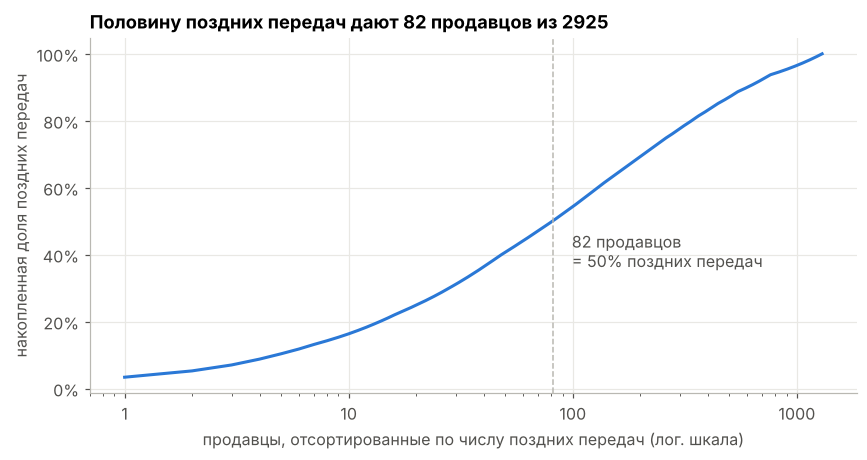

In [10]:
sellers = (df[df.sellers_cnt == 1]
           .groupby('seller_id')
           .agg(orders=('order_id', 'size'), late_handovers=('seller_handover_late', 'sum'))
           .sort_values('late_handovers', ascending=False))
sellers = sellers[sellers.late_handovers > 0]
cum = sellers.late_handovers.cumsum() / sellers.late_handovers.sum()
n_all = df[df.sellers_cnt == 1].seller_id.nunique()
x = range(1, len(cum) + 1)

fig, ax = plt.subplots()
ax.plot(x, cum * 100, color=BLUE, lw=2)
k = int((cum < 0.5).sum()) + 1
ax.axvline(k, color=GRAY, lw=1, ls='--')
ax.annotate(f'{k} продавцов\n= 50% поздних передач', (k, 50), xytext=(12, -30), textcoords='offset points', color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_xlabel('продавцы, отсортированные по числу поздних передач (лог. шкала)')
ax.set_ylabel('накопленная доля поздних передач')
ax.set_title(f'Половину поздних передач дают {k} продавцов из {n_all}')
fig.savefig(IMG / '03_seller_concentration.png')
plt.show()

In [11]:
top = sellers.head(k)
print(f'Доля этих продавцов в общем числе заказов: {top.orders.sum() / len(df[df.sellers_cnt == 1]):.1%}')
print(f'Доля поздних передач у них: {top.late_handovers.sum() / top.orders.sum():.1%}  '
      f'(у остальных: {sellers.iloc[k:].late_handovers.sum() / (len(df[df.sellers_cnt == 1]) - top.orders.sum()):.1%})')

Доля этих продавцов в общем числе заказов: 30.1%
Доля поздних передач у них: 15.0%  (у остальных: 6.4%)


Поздние передачи сильно сконцентрированы: меньше 3% продавцов дают половину из них. Это в основном крупные продавцы — на них приходится около 30% всех заказов. Но дело не только в объёме: поздних передач у них 15% против 6% у остальных, то есть в 2,3 раза чаще. Значит, это не «все немного опаздывают», а конкретный список продавцов, с которым можно работать точечно.

## 5. Регионы

In [12]:
states = run('05_states.sql')
states

,customer_state,orders,promised_days,actual_days,late_pct
0,AL,396,33.1,24.5,24.0
1,MA,713,30.9,21.5,19.6
2,PI,475,30.6,19.4,16.0
3,SE,332,31.2,21.4,15.4
4,CE,1273,31.8,21.2,15.4
5,BA,3253,30.0,19.3,14.0
6,RJ,12310,26.9,15.2,13.5
7,PA,942,37.7,23.7,12.4
8,ES,1992,26.2,15.7,12.2
9,MS,701,26.6,15.5,11.6


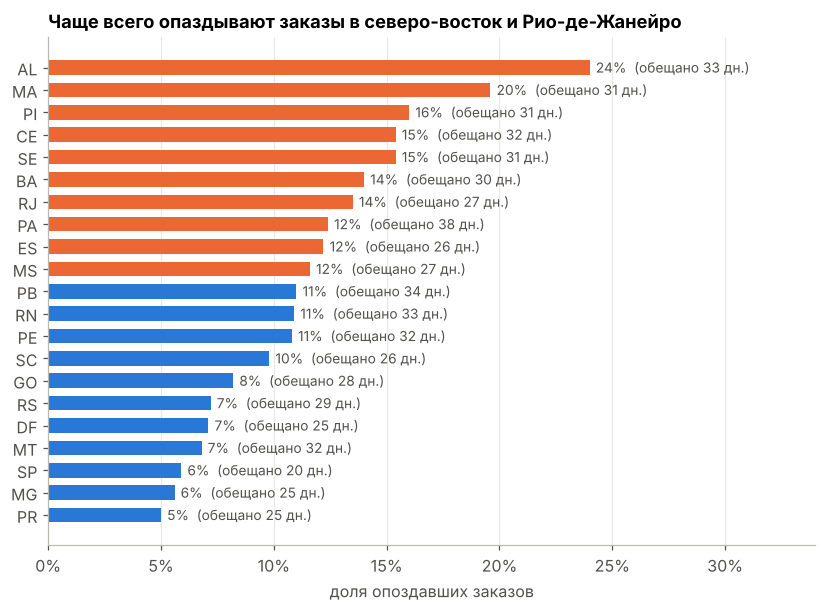

In [13]:
s = states.sort_values('late_pct')
fig, ax = plt.subplots(figsize=(9, 6))
colors = [ORANGE if round(v) >= 12 else BLUE for v in s.late_pct]
bars = ax.barh(s.customer_state, s.late_pct, color=colors, height=0.65)
ax.bar_label(bars, labels=[f'{v:.0f}%  (обещано {p:.0f} дн.)' for v, p in zip(s.late_pct, s.promised_days)],
             padding=4, color=INK, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 34)
ax.grid(axis='y', visible=False)
ax.set_xlabel('доля опоздавших заказов')
ax.set_title('Чаще всего опаздывают заказы в северо-восток и Рио-де-Жанейро')
fig.savefig(IMG / '04_late_by_state.png')
plt.show()

Разница между штатами — в 4 раза: от 5–6% в Сан-Паулу, Минас-Жерайс и Паране до 20–24% в Мараньяне и Алагоасе. Рио-де-Жанейро выделяется: это второй рынок по объёму, а опаздывает каждый седьмой заказ.

Любопытно, что дальние северные штаты (Амазонас, Рондония — в таблицу не попали из-за малого числа заказов) опаздывают редко: им обещают 40–47 дней, и с таким запасом доставка укладывается. Проблема не в расстоянии как таковом, а в том, что для части регионов обещанный срок рассчитан неточно.

## 6. Возвращаются ли покупатели после опоздания

Повторные покупки на Olist вообще редкие — около 3% покупателей делают второй заказ. Проверю, ниже ли эта доля, если первый заказ опоздал. Беру первые заказы до марта 2018, чтобы у покупателей было хотя бы полгода на возврат.

In [14]:
rep = run('06_repeat_purchase.sql')
rep

,first_order_late,customers,returned,returned_pct
0,False,51003,2061.0,4.04
1,True,4262,136.0,3.19


In [15]:
table = [[r.returned, r.customers - r.returned] for r in rep.itertuples()]
chi2, p, *_ = chi2_contingency(table)
print(f'p-value = {p:.4f}')

p-value = 0.0072


После опоздавшего первого заказа возвращается 3.2% покупателей против 4.1% — разница статистически значима (p < 0.01), в относительных цифрах примерно на 20% меньше. В абсолютных числах эффект небольшой, потому что повторных покупок мало в принципе. Основной удар опоздания — по оценке и, через неё, по рейтингу продавца и доверию к площадке.

## Выводы

1. **Опоздание — главный драйвер плохих отзывов.** ~8% заказов опаздывают, и на них приходится около трети оценок 1–2. При опоздании больше недели плохой отзыв ставят ~80% покупателей.
2. **Опоздания идут всплесками.** В обычный месяц 3–6%, в пиковые — 14–21%. Ноябрь объясняется Black Friday, февраль–март 2018 по этим данным объяснить нельзя.
3. **Значимая часть проблемы — на стороне продавцов**, и она сконцентрирована: 82 продавца (менее 3%) дают половину поздних передач в доставку, и опаздывают они с передачей в 2,3 раза чаще остальных.
4. **Сроки для регионов рассчитаны неравномерно.** Для северо-востока и Рио обещание слишком оптимистичное, для севера — с большим запасом.

**Что я бы предложил проверить дальше:**
- Работа с продавцами из этого списка: предупреждения, понижение в выдаче, ограничение на участие в распродажах.
- Пересчитать обещанный срок для штатов с долей опозданий выше 12% — честный срок чуть дольше, вероятно, лучше, чем опоздание.
- Перед Black Friday — заранее увеличивать обещанные сроки или предупреждать покупателей.

**Ограничения:** это наблюдательные данные, а не эксперимент, поэтому эффект опоздания на оценку может быть частично завышен (плохие продавцы могут и опаздывать, и отправлять некачественный товар). Данные за 2016–2018 годы, и о причинах всплесков (погода, перевозчики) в них ничего нет.